# 08 - KAN: referência nos três folds

Uma KAN pequena consegue separar clientes com e sem churn de forma consistente? A primeira etapa usa a variante `neural` e a semente 42. O critério principal é o KS de validação por fold. A comparação com a MLP usa apenas registros da mesma etapa, variante, semente e fold.

In [1]:
# Localiza a raiz do projeto para execução a partir da pasta de notebooks.
import sys
from pathlib import Path

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
sys.path.insert(0, str(raiz))
import pandas as pd
import matplotlib.pyplot as plt
import torch
from src import config as cfg
from src.kan import ajustar
from src.metrics import evaluate_sets, save_results
from src.preprocess import load_preprocessed

torch.set_num_threads(1)

## E0 - Baseline: rede pequena, todas as variáveis

Cada conexão aprende uma spline linear com três intervalos. A grade da primeira camada cobre [0, 1], a escala do treino. A segunda usa [-1, 1] para as ativações internas. Fora da grade, a spline prolonga o segmento extremo. A largura de dez unidades acompanha a MLP de referência. A grade curta limita a flexibilidade inicial.

O Adam minimiza a entropia cruzada binária. A parada antecipada acompanha a perda de validação e recupera os pesos da melhor época segundo a tolerância definida. O teste fica reservado à avaliação final.

In [2]:
# Mantém os hiperparâmetros fixos entre folds.
config = dict(largura=10, intervalos=3, lr=0.001, lote=64, max_epocas=120,
              paciencia=15, min_delta=0.0001)
resultados, curvas = [], {}
for fold in range(1, cfg.K_FOLDS + 1):
    dados = {c: load_preprocessed(fold, c, "neural") for c in ("treino", "validacao")}
    scores, historia, melhor_epoca, segundos = ajustar(dados, config, cfg.SEED)
    curvas[fold] = pd.DataFrame(historia, index=range(1, len(historia) + 1))
    parametros = dict(config, melhor_epoca=melhor_epoca, epocas_rodadas=len(historia))
    resultados.append(evaluate_sets("kan", "neural", fold, scores, hiperparametros=parametros,
                                    etapa="E0_baseline", semente=cfg.SEED))
    print(f"Fold {fold}: melhor época {melhor_epoca}/{len(historia)}, {segundos:.1f} s")
resultado = pd.concat(resultados, ignore_index=True)
save_results(resultado)

Fold 1: melhor época 12/27, 6.3 s
Fold 2: melhor época 9/24, 2.6 s
Fold 3: melhor época 36/51, 6.1 s


In [3]:
# Compara o KS somente onde há uma MLP de referência equivalente.
ks = resultado.pivot(index="fold", columns="conjunto", values="ks")
mlp = pd.read_csv(cfg.REPORTS_TABLES / "resultados_mlp.csv")
ref = mlp.query("etapa == 'E0_baseline' and variante == 'neural' and conjunto == 'validacao' and semente == @cfg.SEED")
ks["mlp_validacao"] = ref.set_index("fold")["ks"]
ks["delta_kan_mlp"] = ks["validacao"] - ks["mlp_validacao"]
print(ks.round(4).to_string(na_rep="—"))
print(f"KS médio de validação: {ks.validacao.mean():.4f}")

conjunto  treino  validacao  mlp_validacao  delta_kan_mlp
fold                                                     
1         0.5577     0.5043         0.5032         0.0012
2         0.5339     0.5157              —              —
3         0.5586     0.5386              —              —
KS médio de validação: 0.5195


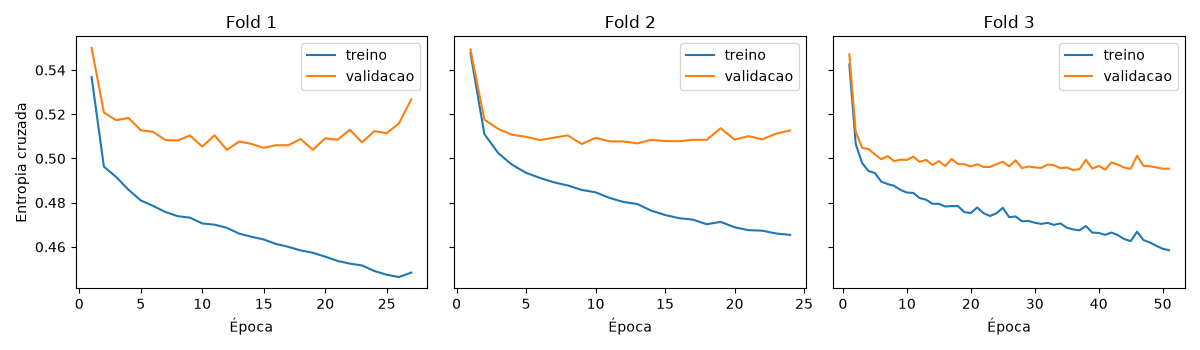

In [4]:
# Usa a mesma escala nos três painéis para comparar as curvas.
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for (fold, curva), eixo in zip(curvas.items(), eixos):
    curva.plot(ax=eixo, title=f"Fold {fold}", xlabel="Época", ylabel="Entropia cruzada")
fig.tight_layout()
plt.show()

## Registro do processo

A configuração E0 atingiu KS médio de validação de 0.5195, com valores entre 0.5043 e 0.5386. No fold 1, a diferença KAN menos MLP foi de +0.0012. Os traços na tabela indicam folds sem registro equivalente da MLP.

Esta rodada estabelece a referência com uma única semente. Para investigar a resolução das splines, a próxima comparação proposta mantém a largura e o protocolo de treinamento e altera apenas o número de intervalos.